# LM28 Lab — Mean–Variance Optimization

Companion notebook to **From Calculus to Kelly, LM28**. It rebuilds the module's exhibits and computational examples from E5's daily total returns and U28's sector price indices. It also computes the widget's starting values, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: E5's two frames, the first window, $A$, $A_{\mathrm w}$, the test period; Exhibit 1 |
| 2 | The minimum-variance portfolio by hand (Example 1): $\Sigma\mathbf w^{\mathrm{mv}}=\sigma^2_{\min}\mathbf 1$, betas and risk shares |
| 3 | The frontier (Exhibit 3), equal weights inside it (Example 3) and two-fund separation |
| 4 | The tangency portfolio (Example 4) at $r_f$ = 0, 1.5% and 2%, the tangency betas, the capital market line at 10% (Example 5) and the widget's starting values |
| 5 | Sensitivity to the means: Exhibit 4, Example 6 and (28.9) against the exact changes |
| 6 | The first window held to the end: Exhibit 5, Example 7, Example 8 |
| 7 | U28 (Example 2, Exhibit 2) and its halves |
| 8 | The KKT system and cvxpy (Example 9): statuses, gaps, residuals and the sign of the duals |
| 9 | Practice problems 10, 11 and 12 |
| 10 | The 92 windows: $\mathbf w^{\mathrm{mv}}$ against R3's targets, and the 22 windows with $r_f\ge\mu_{\mathrm{mv}}$ |
| 11 | Extension: adding the funds one at a time |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds five files, and the notebook reads nothing outside `data/`:

- `e5_estimation.csv` and `e5_wealth.csv`: E5's estimation frame (the dates on which all five funds have a one-session total return) and its wealth frame (every session, a halted fund earning 0, with a `traded` flag), one row per date and fund. They are derived from FinMind `TaiwanStockPrice`, `TaiwanStockDividendResult` and `TaiwanStockSplitPrice`.
- `rule_targets.csv`: the through case's trades. This lab reads R3's rows only: the 92 signal and trade dates, and R3's long-only minimum-variance targets for Part 10.
- `sectors_close_raw.csv` and `sectors_close_repairs.csv`: the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, and the 561 closes copied from another date or series with their official 13:30:00 values from `TaiwanStockEvery5SecondsIndex` (a paid dataset: on the free plan the values are empty, the notebook drops those closes, and U28's numbers differ slightly from the book's).

**Conventions (as in the module).**

- The funds, in order: 0050, 00646, 00679B, 00635U, 00642U. Years are calendar days / 365.25 from the base close (17 January 2017) to 8 October 2026; $A=T/\text{years}$ for the estimation frame and $A_{\mathrm w}$ for the wealth frame.
- The first window is the 504 estimation rows through the first signal (27 February 2019); $\boldsymbol\mu=A\bar{\mathbf R}$ and $\Sigma=A\hat\Sigma$ with divisor $T$, annual, treated as known; $r_f=1.5\%$ a year, simple, $\mathbf e=\boldsymbol\mu-r_f\mathbf 1$.
- Every linear system is solved with `np.linalg.solve`, never with an explicit inverse.
- Held portfolios keep constant weights, rebalanced every session, without costs, and earn $\mathbf w^{\top}\mathbf R_t$ on the wealth frame after the trade of 4 March 2019; joint statistics of the test period use the estimation frame's rows after that date.
- Standard errors: (20.2) for means, $\text{vol}\sqrt{(\operatorname{Kurt}-1)/(4T)}$ with the raw kurtosis for volatilities (iid).
- A short is a weight below $-10^{-6}$; gross exposure is $\lVert\mathbf w\rVert_1$.

In [1]:
import math
from datetime import date
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

DATA = Path("data")
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
RF = 0.015                                   # the illustrative riskless rate, a year, simple
WINDOW = 504
LAST = "2026-10-08"
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed, kept=True):
    # print a value next to the module's printed value; assert equality unless the free plan dropped closes
    got = format(value, fmt)
    note = "" if got == printed else ("   MISMATCH" if kept else "   (differs: closes were dropped)")
    print(f"{label}: {got}   [book: {printed}]{note}")
    assert got == printed or not kept, (label, got, printed)


def cov0(x):
    # the sample covariance matrix with divisor T, assets in columns (np.cov(x, rowvar=False, ddof=0))
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]


def mv(mu, S, rf=RF):
    # LM28's closed forms: (28.2) and the ingredients of (28.4)-(28.6)
    one = np.ones(len(mu))
    x = np.linalg.solve(S, one)                       # Sigma^-1 1
    s2 = 1 / x.sum()
    wmv = s2 * x
    mumv = float(mu @ wmv)
    d = mu - mumv * one
    dirn = np.linalg.solve(S, d)                      # Sigma^-1 (mu - mu_mv 1)
    e = mu - rf * one
    y = np.linalg.solve(S, e)                         # Sigma^-1 e
    return {"s2min": s2, "wmv": wmv, "mumv": mumv, "srinf2": float(d @ dirn), "dir": dirn, "e": e, "y": y,
            "den": float(y.sum()), "sr2": float(e @ y), "wtan": y / y.sum()}


def front_var(o, mp):
    return o["s2min"] + (mp - o["mumv"]) ** 2 / o["srinf2"]          # (28.5)


def front_w(o, mp):
    return o["wmv"] + (mp - o["mumv"]) / o["srinf2"] * o["dir"]       # (28.4)


def vec(w, plus=False):
    return "(" + ", ".join(f"{100 * v:{'+' if plus else ''}.1f}" for v in w) + ")"


def kurt(r):
    c = r - r.mean()
    return float((c**4).mean() / (c**2).mean() ** 2)

## Part 1 — Data, the first window and the test period

The two frames come in long form, one row per date and fund. Fund codes must be read as text: `0050` would otherwise become the integer 50. The signal and trade dates are R3's rows of `rule_targets.csv`: the first signal is the first month-end with 504 estimation rows.

In [2]:
ov = {"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8}
est_long = pl.read_csv(DATA / "e5_estimation.csv", schema_overrides=ov)
wl = pl.read_csv(DATA / "e5_wealth.csv", schema_overrides=ov)
est = est_long.pivot(on="fund", index="date", values="R").sort("date").select(["date", *FUNDS])
wealth = wl.pivot(on="fund", index="date", values="R").sort("date").select(["date", *FUNDS])
r3 = (pl.read_csv(DATA / "rule_targets.csv", schema_overrides={"signal": pl.Utf8, "trade": pl.Utf8})
        .filter(pl.col("rule") == pl.lit("R3")).sort("signal"))
base = est_long["base"][0]
years = (date.fromisoformat(LAST) - date.fromisoformat(base)).days / 365.25
X, dates = est.select(FUNDS).to_numpy(), est["date"].to_list()
W, wdates = wealth.select(FUNDS).to_numpy(), wealth["date"].to_list()
A, Aw = len(dates) / years, len(wdates) / years
show("estimation frame T", len(dates), ",d", "2,362")
show("wealth frame sessions", len(wdates), ",d", "2,368")
show("A", A, ".2f", "242.95")
show("A_w", Aw, ".2f", "243.57")
show("r_f / A in bp", RF / A * 1e4, ".3f", "0.617")

signal0, trade0 = r3["signal"][0], r3["trade"][0]
rows = dates.index(signal0) + 1
x = X[rows - WINDOW:rows]
print(f"first signal {signal0}, trade {trade0}; window {dates[rows - WINDOW]} .. {dates[rows - 1]} ({len(x)} rows)")
mu, S = A * x.mean(axis=0), A * cov0(x)
sd = np.sqrt(np.diag(S))
Cw = S / np.outer(sd, sd)
np.linalg.cholesky(S)                                   # raises LinAlgError if S is not positive definite
Wt = W[[i for i, d in enumerate(wdates) if d > trade0]]
Xt = X[[i for i, d in enumerate(dates) if d > trade0]]
show("test returns (wealth frame)", len(Wt), ",d", "1,851")
show("test rows (estimation frame)", len(Xt), ",d", "1,845")
yt = (date.fromisoformat(LAST) - date.fromisoformat(trade0)).days / 365.25
show("test years", yt, ".2f", "7.60")
print("wealth dates missing from the estimation frame:", sorted(set(d for d in wdates if d > trade0) - set(dates)))

estimation frame T: 2,362   [book: 2,362]
wealth frame sessions: 2,368   [book: 2,368]
A: 242.95   [book: 242.95]
A_w: 243.57   [book: 243.57]
r_f / A in bp: 0.617   [book: 0.617]
first signal 2019-02-27, trade 2019-03-04; window 2017-02-13 .. 2019-02-27 (504 rows)
test returns (wealth frame): 1,851   [book: 1,851]
test rows (estimation frame): 1,845   [book: 1,845]
test years: 7.60   [book: 7.60]
wealth dates missing from the estimation frame: ['2025-06-11', '2025-06-12', '2025-06-13', '2025-06-16', '2025-06-17', '2025-06-18']


Exhibit 1's fund rows: the window's means and volatilities (estimation frame, $A$), and each fund's test volatility on its own one-session dates (traded on the day and on the previous session), annualized by its own sessions per year over E5.

In [3]:
tr = wl.pivot(on="fund", index="date", values="traded").sort("date").select(FUNDS).to_numpy()
one_sess = tr & np.vstack([np.ones((1, 5), dtype=bool), tr[:-1]])     # traded on t and on the previous session
A_own = one_sess.sum(axis=0) / years
after = np.array([d > trade0 for d in wdates])
test_vol = [W[after & one_sess[:, j], j].std(ddof=0) * math.sqrt(A_own[j]) for j in range(5)]
o = mv(mu, S)
case = pl.DataFrame({"fund": FUNDS, "window mean %": 100 * mu, "window vol %": 100 * sd,
                     "test vol %": 100 * np.array(test_vol), "w_mv %": 100 * o["wmv"], "w_tan %": 100 * o["wtan"]})
print(case.with_columns(pl.col(pl.Float64).round(1)))
for j, p in enumerate(["21.6", "17.2", "14.6", "18.1", "40.7"]):
    show(f"test volatility {FUNDS[j]}", 100 * test_vol[j], ".1f", p)

shape: (5, 6)
┌────────┬───────────────┬──────────────┬────────────┬────────┬─────────┐
│ fund   ┆ window mean % ┆ window vol % ┆ test vol % ┆ w_mv % ┆ w_tan % │
│ ---    ┆ ---           ┆ ---          ┆ ---        ┆ ---    ┆ ---     │
│ str    ┆ f64           ┆ f64          ┆ f64        ┆ f64    ┆ f64     │
╞════════╪═══════════════╪══════════════╪════════════╪════════╪═════════╡
│ 0050   ┆ 7.5           ┆ 13.5         ┆ 21.6       ┆ 10.7   ┆ 11.8    │
│ 00646  ┆ 10.0          ┆ 11.9         ┆ 17.2       ┆ 22.5   ┆ 62.6    │
│ 00679B ┆ 2.6           ┆ 8.5          ┆ 14.6       ┆ 41.4   ┆ 37.8    │
│ 00635U ┆ 0.8           ┆ 9.4          ┆ 18.1       ┆ 25.0   ┆ 2.6     │
│ 00642U ┆ -1.4          ┆ 23.2         ┆ 40.7       ┆ 0.4    ┆ -14.7   │
└────────┴───────────────┴──────────────┴────────────┴────────┴─────────┘
test volatility 0050: 21.6   [book: 21.6]
test volatility 00646: 17.2   [book: 17.2]
test volatility 00679B: 14.6   [book: 14.6]
test volatility 00635U: 18.1   [book: 18.1]

## Part 2 — The minimum-variance portfolio by hand

Solve $\Sigma\mathbf x=\mathbf 1$ and rescale, (28.2). Then check that every fund's covariance with the mix is $\sigma^2_{\min}$, so that every beta to it is 1 and every risk share, $w_i(\Sigma\mathbf w)_i/\sigma_p^2$, equals its weight (Example 1).

In [4]:
xs = np.linalg.solve(S, np.ones(5))
w_mv = xs / xs.sum()
s2min = 1 / xs.sum()
show("w_mv", vec(w_mv), "s", "(10.7, 22.5, 41.4, 25.0, 0.4)")
show("sigma_min^2", s2min, ".7f", "0.0025152")
show("sigma_min", 100 * math.sqrt(s2min), ".2f", "5.02")
show("mu_mv", 100 * (mu @ w_mv), ".2f", "4.34")
show("lambda* = 2 sigma_min^2", 2 * s2min, ".5f", "0.00503")
cov_mv = S @ w_mv
print("covariances with w_mv:", np.round(cov_mv, 7), " largest gap to sigma_min^2:", np.abs(cov_mv - s2min).max())
print("risk shares - weights, largest:", np.abs(w_mv * cov_mv / s2min - w_mv).max())
show("smallest weight (oil)", 100 * w_mv.min(), ".2f", "0.36")

w_mv: (10.7, 22.5, 41.4, 25.0, 0.4)   [book: (10.7, 22.5, 41.4, 25.0, 0.4)]
sigma_min^2: 0.0025152   [book: 0.0025152]
sigma_min: 5.02   [book: 5.02]
mu_mv: 4.34   [book: 4.34]
lambda* = 2 sigma_min^2: 0.00503   [book: 0.00503]
covariances with w_mv: [0.0025152 0.0025152 0.0025152 0.0025152 0.0025152]  largest gap to sigma_min^2: 1.3010426069826053e-18
risk shares - weights, largest: 1.1102230246251565e-16
smallest weight (oil): 0.36   [book: 0.36]


## Part 3 — The frontier and two-fund separation

(28.4) and (28.5) with $\mathrm{SR}_\infty^2=(\boldsymbol\mu-\mu_{\mathrm{mv}}\mathbf 1)^{\top}\Sigma^{-1}(\boldsymbol\mu-\mu_{\mathrm{mv}}\mathbf 1)$, the chart of Exhibit 3, and Example 3. Two-fund separation: any two frontier portfolios rebuild every other one.

SR_inf: 0.675   [book: 0.675]
equal weights mean: 3.913   [book: 3.913]
equal weights vol: 7.38   [book: 7.38]
frontier vol at that mean: 5.05   [book: 5.05]
efficient mean at that vol: 7.99   [book: 7.99]
its weights: (11.7, 58.8, 38.1, 4.7, -13.3)   [book: (11.7, 58.8, 38.1, 4.7, -13.3)]
lambda_mu = d sigma_p^2 / d mu_p: 0.161   [book: 0.161]
lambda = 2 sigma_min^2 - mu_mv lambda_mu: -0.00193   [book: -0.00193]
00646's weight per point of target mean: +9.9   [book: +9.9]
gold's weight per point of target mean: -5.6   [book: -5.6]
two-fund separation, largest gap: 2.7755575615628914e-17


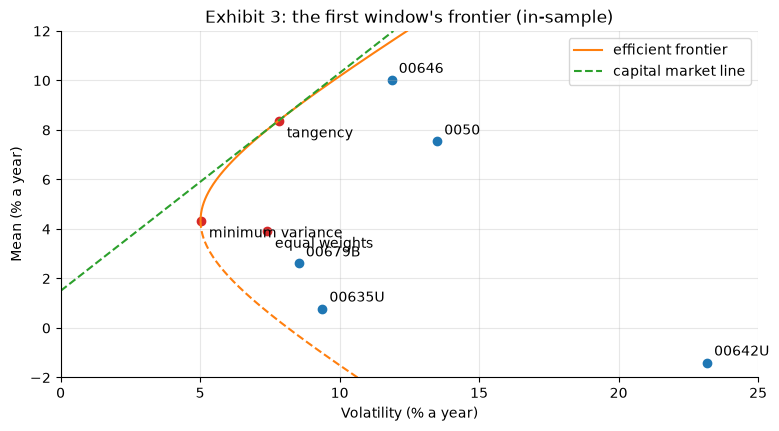

In [5]:
st, mtan = math.sqrt(o["wtan"] @ S @ o["wtan"]), float(mu @ o["wtan"])
wN = np.full(5, 0.2)
mN, sN = float(mu @ wN), math.sqrt(wN @ S @ wN)
me = o["mumv"] + math.sqrt(o["srinf2"] * (sN**2 - o["s2min"]))          # the efficient mean at equal weights' vol
show("SR_inf", math.sqrt(o["srinf2"]), ".3f", "0.675")
show("equal weights mean", 100 * mN, ".3f", "3.913")
show("equal weights vol", 100 * sN, ".2f", "7.38")
show("frontier vol at that mean", 100 * math.sqrt(front_var(o, mN)), ".2f", "5.05")
show("efficient mean at that vol", 100 * me, ".2f", "7.99")
show("its weights", vec(front_w(o, me)), "s", "(11.7, 58.8, 38.1, 4.7, -13.3)")
lam_mu = 2 * (me - o["mumv"]) / o["srinf2"]
show("lambda_mu = d sigma_p^2 / d mu_p", lam_mu, ".3f", "0.161")
show("lambda = 2 sigma_min^2 - mu_mv lambda_mu", 2 * o["s2min"] - o["mumv"] * lam_mu, ".5f", "-0.00193")
slope = 0.01 * o["dir"] / o["srinf2"]
show("00646's weight per point of target mean", 100 * slope[1], "+.1f", "+9.9")
show("gold's weight per point of target mean", 100 * slope[3], "+.1f", "-5.6")

# two-fund separation: rebuild the frontier portfolio at me from two others, w_mv and the frontier at 10%
wa, ma, wb, mb = o["wmv"], o["mumv"], front_w(o, 0.10), 0.10
rebuilt = wa + (me - ma) / (mb - ma) * (wb - wa)
print("two-fund separation, largest gap:", np.abs(rebuilt - front_w(o, me)).max())

ms = np.linspace(-0.02, 0.12, 300)
vs = np.sqrt([front_var(o, m) for m in ms])
fig, ax = plt.subplots()
ax.plot(100 * vs[ms >= o["mumv"]], 100 * ms[ms >= o["mumv"]], color="C1", label="efficient frontier")
ax.plot(100 * vs[ms < o["mumv"]], 100 * ms[ms < o["mumv"]], color="C1", ls="--")
sr = math.sqrt(o["sr2"])
ax.plot([0, 100 * (0.12 - RF) / sr], [100 * RF, 12], color="C2", ls="--", label="capital market line")
ax.scatter(100 * sd, 100 * mu, color="C0")
for j, f in enumerate(FUNDS):
    ax.annotate(f, (100 * sd[j], 100 * mu[j]), textcoords="offset points", xytext=(5, 5))
for (px, py), lab in (((math.sqrt(o["s2min"]), o["mumv"]), "minimum variance"), ((st, mtan), "tangency"),
                      ((sN, mN), "equal weights")):
    ax.scatter(100 * px, 100 * py, color="C3")
    ax.annotate(lab, (100 * px, 100 * py), textcoords="offset points", xytext=(6, -12))
ax.set(xlim=(0, 25), ylim=(-2, 12), xlabel="Volatility (% a year)", ylabel="Mean (% a year)",
       title="Exhibit 3: the first window's frontier (in-sample)")
ax.legend()
plt.show()

## Part 4 — The tangency portfolio, the betas and the capital market line

(28.6) and (28.7) at $r_f=1.5\%$, then at 0% and 2% (Example 4). The tangency betas $(\Sigma\mathbf w^{\mathrm{tan}})_i/\sigma_{\tan}^2$ equal $e_i/(\mu_{\tan}-r_f)$, by (27.5). The capital market line at 10% volatility is Example 5.

In [6]:
show("mu_mv (3 dp)", 100 * o["mumv"], ".3f", "4.335")
show("1' Sigma^-1 e", o["den"], ".2f", "11.27")
print("1' Sigma^-1 e - (mu_mv - r_f) / sigma_min^2:", o["den"] - (o["mumv"] - RF) / o["s2min"])
show("w_tan", vec(o["wtan"]), "s", "(11.8, 62.6, 37.8, 2.6, -14.7)")
show("gross exposure", np.abs(o["wtan"]).sum(), ".2f", "1.29")
show("mean", 100 * mtan, ".3f", "8.376")
show("volatility", 100 * st, ".3f", "7.810")
show("SR*", sr, ".3f", "0.880")
show("best single fund (00646)", (mu[1] - RF) / sd[1], ".2f", "0.72")
show("SR*^2", o["sr2"], ".4f", "0.7750")
show("SR_inf^2 + ((mu_mv - r_f) / sigma_min)^2", o["srinf2"] + (o["mumv"] - RF) ** 2 / o["s2min"], ".4f", "0.7750")
t = (me - o["mumv"]) / (mtan - o["mumv"])
show("two-fund separation t", t, ".3f", "0.905")
print("E3's weights - (w_mv + t (w_tan - w_mv)), largest:", np.abs(front_w(o, me) - (o["wmv"] + t * (o["wtan"] - o["wmv"]))).max())
beta = S @ o["wtan"] / (o["wtan"] @ S @ o["wtan"])
print("tangency betas:", np.round(beta, 4), " largest gap to e_i / (mu_tan - r_f):",
      np.abs(beta - o["e"] / (mtan - RF)).max())
for rf, pw, psr in ((0.0, "(11.4, 48.7, 39.1, 10.3, -9.5)", "1.10"), (0.02, "(12.0, 71.1, 37.0, -2.2, -18.0)", "0.82")):
    orf = mv(mu, S, rf)
    show(f"w_tan at r_f {rf:.0%}", vec(orf["wtan"]), "s", pw)
    show(f"SR* at r_f {rf:.0%}", math.sqrt(orf["sr2"]), ".2f", psr)

delta = sr / 0.10                                        # (28.8): volatility SR*/delta = 10%
f = o["y"] / delta
show("CML mean at 10%", 100 * (RF + sr * 0.10), ".2f", "10.30")
show("delta", delta, ".2f", "8.80")
show("L", f.sum(), ".2f", "1.28")
show("exposures", vec(f), "s", "(15.1, 80.1, 48.4, 3.3, -18.9)")
print("volatility of f:", math.sqrt(f @ S @ f))

# the widget's starting values: the sliders' rounded means and correlation, every other entry exact
mu_s, S_s = mu.copy(), S.copy()
mu_s[1], mu_s[3] = 0.100, 0.008
S_s[0, 1] = S_s[1, 0] = 0.54 * sd[0] * sd[1]
os_ = mv(mu_s, S_s)
show("widget, rounded state: w_tan", vec(os_["wtan"]), "s", "(11.8, 62.4, 37.8, 2.7, -14.7)")
show("widget, rounded state: SR*", math.sqrt(os_["sr2"]), ".3f", "0.878")
show("widget, rounded state: mu_mv", 100 * os_["mumv"], ".2f", "4.33")

mu_mv (3 dp): 4.335   [book: 4.335]
1' Sigma^-1 e: 11.27   [book: 11.27]
1' Sigma^-1 e - (mu_mv - r_f) / sigma_min^2: 1.7763568394002505e-15
w_tan: (11.8, 62.6, 37.8, 2.6, -14.7)   [book: (11.8, 62.6, 37.8, 2.6, -14.7)]
gross exposure: 1.29   [book: 1.29]
mean: 8.376   [book: 8.376]
volatility: 7.810   [book: 7.810]
SR*: 0.880   [book: 0.880]
best single fund (00646): 0.72   [book: 0.72]
SR*^2: 0.7750   [book: 0.7750]
SR_inf^2 + ((mu_mv - r_f) / sigma_min)^2: 0.7750   [book: 0.7750]
two-fund separation t: 0.905   [book: 0.905]
E3's weights - (w_mv + t (w_tan - w_mv)), largest: 6.938893903907228e-17
tangency betas: [ 0.8781  1.2404  0.1617 -0.1041 -0.421 ]  largest gap to e_i / (mu_tan - r_f): 2.220446049250313e-16
w_tan at r_f 0%: (11.4, 48.7, 39.1, 10.3, -9.5)   [book: (11.4, 48.7, 39.1, 10.3, -9.5)]
SR* at r_f 0%: 1.10   [book: 1.10]
w_tan at r_f 2%: (12.0, 71.1, 37.0, -2.2, -18.0)   [book: (12.0, 71.1, 37.0, -2.2, -18.0)]
SR* at r_f 2%: 0.82   [book: 0.82]
CML mean at 10%: 10.30   [

## Part 5 — How the tangency weights react to the means

Exhibit 4: recompute (28.6) with one mean raised by 1 point. Example 6 and the Jacobian (28.9), $(I-\mathbf w^{\mathrm{tan}}\mathbf 1^{\top})\Sigma^{-1}/(\mathbf 1^{\top}\Sigma^{-1}\mathbf e)$, whose $\Sigma^{-1}$ is found by solving against the identity.

In [7]:
dW = np.zeros((5, 5))
for j in range(5):
    m2 = mu.copy()
    m2[j] += 0.01
    dW[:, j] = mv(m2, S)["wtan"] - o["wtan"]
table = pl.DataFrame({"weight of": FUNDS} | {f"{f} mean +1": 100 * dW[:, j] for j, f in enumerate(FUNDS)})
print(table.with_columns(pl.col(pl.Float64).round(1)))
Sinv = np.linalg.solve(S, np.eye(5))
J = (np.eye(5) - np.outer(o["wtan"], np.ones(5))) @ Sinv / o["den"]
se = sd / math.sqrt(WINDOW / A)                          # (20.2): A s / sqrt(T), annual
show("SEs of the means", "(" + ", ".join(f"{100 * v:.1f}" for v in se) + ")", "s", "(9.4, 8.2, 5.9, 6.5, 16.1)")
show("gold: 1 point in SE units", 0.01 / se[3], ".2f", "0.15")
show("gold's weight before", 100 * o["wtan"][3], ".3f", "2.576")
show("gold's weight after", 100 * (o["wtan"][3] + dW[3, 3]), ".3f", "12.845")
show("(28.9)'s linear prediction", 100 * 0.01 * J[3, 3], ".1f", "11.2")
show("exposure change at delta 8.80", vec(0.01 * Sinv[:, 3] / delta, plus=True), "s", "(-2.0, +3.2, -3.6, +14.6, -0.9)")
show("the change in L, points", 100 * 0.01 * Sinv[:, 3].sum() / delta, ".1f", "11.3")

shape: (5, 6)
┌───────────┬──────────────┬───────────────┬────────────────┬────────────────┬────────────────┐
│ weight of ┆ 0050 mean +1 ┆ 00646 mean +1 ┆ 00679B mean +1 ┆ 00635U mean +1 ┆ 00642U mean +1 │
│ ---       ┆ ---          ┆ ---           ┆ ---            ┆ ---            ┆ ---            │
│ str       ┆ f64          ┆ f64           ┆ f64            ┆ f64            ┆ f64            │
╞═══════════╪══════════════╪═══════════════╪════════════════╪════════════════╪════════════════╡
│ 0050      ┆ 6.6          ┆ -4.8          ┆ 0.5            ┆ -2.4           ┆ -0.1           │
│ 00646     ┆ -6.4         ┆ 4.7           ┆ -7.3           ┆ -2.8           ┆ -1.2           │
│ 00679B    ┆ 0.8          ┆ -2.1          ┆ 7.6            ┆ -5.7           ┆ 0.1            │
│ 00635U    ┆ -1.6         ┆ 2.1           ┆ -2.8           ┆ 10.3           ┆ -0.7           │
│ 00642U    ┆ 0.5          ┆ 0.0           ┆ 2.0            ┆ 0.6            ┆ 1.9            │
└───────────┴─────────────

## Part 6 — The first window held to the end

Hold $\mathbf w^{\mathrm{mv}}$ and $\mathbf w^{\mathrm{tan}}$ at constant weights on the wealth frame's 1,851 returns (Exhibit 5, Example 8), then split each variance by (28.3) on the estimation frame's 1,845 test rows (Example 7).

test sigma_min^2: 0.00927   [book: 0.00927]
test sigma_min: 9.63   [book: 9.63]
w_mv: realized vol 10.05% (SE 0.40, raw kurtosis 12.6), mean 9.14% (SE 3.6), log growth 8.63% a year, smallest 1 + R 0.949
w_mv realized vol: 10.05   [book: 10.05]
w_mv weight-error term: 0.00081   [book: 0.00081]
w_mv total: 0.01008   [book: 0.01008]
w_mv vol on the test rows: 10.04   [book: 10.04]
w_mv added by the weight error: 0.41   [book: 0.41]
w_tan: realized vol 14.15% (SE 0.53, raw kurtosis 11.6), mean 10.79% (SE 5.1), log growth 9.79% a year, smallest 1 + R 0.929
w_tan realized vol: 14.15   [book: 14.15]
w_tan weight-error term: 0.01071   [book: 0.01071]
w_tan total: 0.01998   [book: 0.01998]
w_tan vol on the test rows: 14.14   [book: 14.14]
w_tan added by the weight error: 4.51   [book: 4.51]
ex-post w_mv: (8.0, 22.4, 46.1, 17.0, 6.5)   [book: (8.0, 22.4, 46.1, 17.0, 6.5)]
ex-post w_tan: (69.7, 8.8, -11.9, 27.6, 5.9)   [book: (69.7, 8.8, -11.9, 27.6, 5.9)]
test vols with the window's correlations

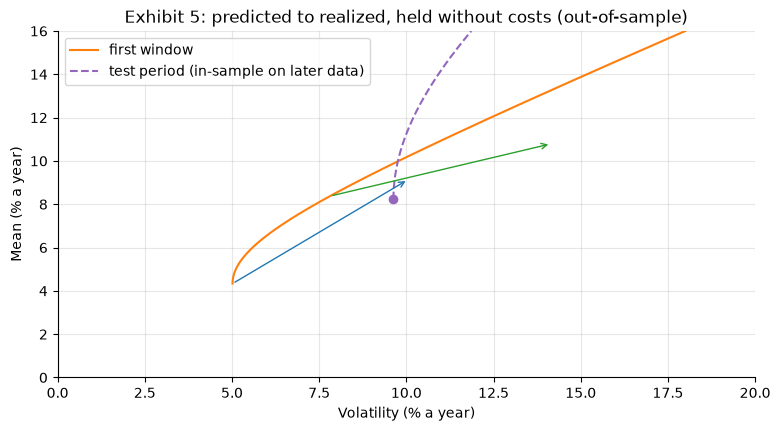

In [8]:
St = A * cov0(Xt)
ot = mv(A * Xt.mean(axis=0), St)
show("test sigma_min^2", ot["s2min"], ".5f", "0.00927")
show("test sigma_min", 100 * math.sqrt(ot["s2min"]), ".2f", "9.63")
for name, w, pv_, pe, ptot, pvol, padd in (("w_mv", o["wmv"], "10.05", "0.00081", "0.01008", "10.04", "0.41"),
                                           ("w_tan", o["wtan"], "14.15", "0.01071", "0.01998", "14.14", "4.51")):
    r = Wt @ w
    vol = r.std(ddof=0) * math.sqrt(Aw)
    k = kurt(r)
    print(f"{name}: realized vol {100 * vol:.2f}% (SE {100 * vol * math.sqrt((k - 1) / (4 * len(r))):.2f}, raw kurtosis "
          f"{k:.1f}), mean {100 * r.mean() * Aw:.2f}% (SE {100 * r.std(ddof=0) * Aw / math.sqrt(len(r)):.1f}), log growth "
          f"{100 * np.log1p(r).sum() / yt:.2f}% a year, smallest 1 + R {(1 + r).min():.3f}")
    show(f"{name} realized vol", 100 * vol, ".2f", pv_)
    dv = (w - ot["wmv"]) @ St @ (w - ot["wmv"])
    show(f"{name} weight-error term", dv, ".5f", pe)
    show(f"{name} total", w @ St @ w, ".5f", ptot)
    show(f"{name} vol on the test rows", 100 * math.sqrt(w @ St @ w), ".2f", pvol)
    show(f"{name} added by the weight error", 100 * (math.sqrt(w @ St @ w) - math.sqrt(ot["s2min"])), ".2f", padd)
show("ex-post w_mv", vec(ot["wmv"]), "s", "(8.0, 22.4, 46.1, 17.0, 6.5)")
show("ex-post w_tan", vec(ot["wtan"]), "s", "(69.7, 8.8, -11.9, 27.6, 5.9)")
sdt = np.sqrt(np.diag(St))
Ct = St / np.outer(sdt, sdt)
cf = 1 / math.sqrt(np.linalg.solve(np.outer(sdt, sdt) * Cw, np.ones(5)).sum())
show("test vols with the window's correlations", 100 * cf, ".2f", "8.35")
print(f"0050-00679B correlation {Cw[0, 2]:.2f} -> {Ct[0, 2]:.2f}; 00646-00679B {Cw[1, 2]:.2f} -> {Ct[1, 2]:.2f}")

fig, ax = plt.subplots()
for oo, col, ls, lab in ((o, "C1", "-", "first window"), (ot, "C4", "--", "test period (in-sample on later data)")):
    ms = np.linspace(oo["mumv"], 0.16, 200)
    ax.plot(100 * np.sqrt([front_var(oo, m) for m in ms]), 100 * ms, color=col, ls=ls, label=lab)
for w, col in ((o["wmv"], "C0"), (o["wtan"], "C2")):
    r = Wt @ w
    ax.annotate("", xy=(100 * r.std(ddof=0) * math.sqrt(Aw), 100 * r.mean() * Aw),
                xytext=(100 * math.sqrt(w @ S @ w), 100 * mu @ w), arrowprops={"arrowstyle": "->", "color": col})
ax.scatter(100 * math.sqrt(ot["s2min"]), 100 * ot["mumv"], color="C4")
ax.set(xlim=(0, 20), ylim=(0, 16), xlabel="Volatility (% a year)", ylabel="Mean (% a year)",
       title="Exhibit 5: predicted to realized, held without costs (out-of-sample)")
ax.legend()
plt.show()

## Part 7 — U28: minimum variance on 28 sector indices

FinMind's `TaiwanStockPrice` serves the sector indices with some closes copied from another date or series; the book replaces each with its official 13:30:00 value, as Lab 23 does. On FinMind's free plan the 13:30:00 values are empty, so the cell **drops** those closes instead, never estimating them: the numbers then differ slightly from Example 2.

full data: True; U28 T = 4382, A = 245.48
shorts: 12   [book: 12]
gross: 2.24   [book: 2.24]
sigma_min: 10.98   [book: 10.98]
CommunicationsInternet's weight: 53.6   [book: 53.6]
Optoelectronic's weight: -10.8   [book: -10.8]
condition number: 108.1   [book: 108.1]
half 1 shorts: 10   [book: 10]
half 1 gross: 2.44   [book: 2.44]
half 2 shorts: 13   [book: 13]
half 2 gross: 2.06   [book: 2.06]
cosine of the halves' w_mv: 0.690   [book: 0.690]


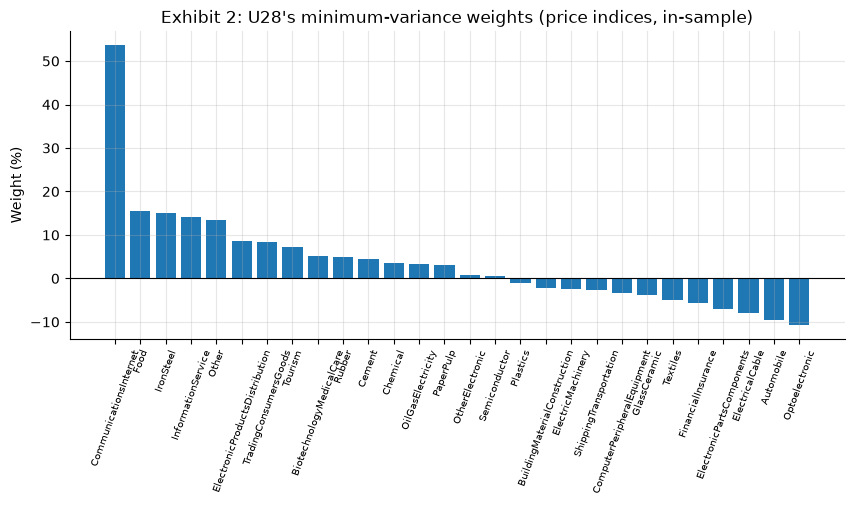

In [9]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
FULL_DATA = int(rep["close_1330"].is_not_null().sum()) == rep.height
U28 = [c for c in raw.columns if c not in ("date", "TAIEX", *AGGREGATES)]
closes = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
ret = (closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in U28]).slice(1)
             .filter(pl.all_horizontal([pl.col(c).is_not_null() for c in U28])))
XU = ret.select(U28).to_numpy()
yu = (date.fromisoformat(LAST_CLOSE) - date.fromisoformat(FIRST_CLOSE)).days / 365.25
AU = XU.shape[0] / yu
print(f"full data: {FULL_DATA}; U28 T = {XU.shape[0]}, A = {AU:.2f}")
SU = AU * cov0(XU)
ou = mv(AU * XU.mean(axis=0), SU)
show("shorts", int((ou["wmv"] < -1e-6).sum()), "d", "12", kept=FULL_DATA)
show("gross", np.abs(ou["wmv"]).sum(), ".2f", "2.24", kept=FULL_DATA)
show("sigma_min", 100 * math.sqrt(ou["s2min"]), ".2f", "10.98", kept=FULL_DATA)
show("CommunicationsInternet's weight", 100 * ou["wmv"][U28.index("CommunicationsInternet")], ".1f", "53.6", kept=FULL_DATA)
show("Optoelectronic's weight", 100 * ou["wmv"][U28.index("Optoelectronic")], ".1f", "-10.8", kept=FULL_DATA)
ev = np.linalg.eigvalsh(SU)
show("condition number", ev[-1] / ev[0], ".1f", "108.1", kept=FULL_DATA)
H = XU.shape[0] // 2
halves = [mv(AU * part.mean(axis=0), AU * cov0(part)) for part in (XU[:H], XU[-H:])]
for k, (h, ps, pg) in enumerate(zip(halves, ("10", "13"), ("2.44", "2.06"))):
    show(f"half {k + 1} shorts", int((h["wmv"] < -1e-6).sum()), "d", ps, kept=FULL_DATA)
    show(f"half {k + 1} gross", np.abs(h["wmv"]).sum(), ".2f", pg, kept=FULL_DATA)
a_, b_ = halves[0]["wmv"], halves[1]["wmv"]
show("cosine of the halves' w_mv", a_ @ b_ / (np.linalg.norm(a_) * np.linalg.norm(b_)), ".3f", "0.690", kept=FULL_DATA)
order = np.argsort(-ou["wmv"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(28), 100 * ou["wmv"][order])
ax.set_xticks(range(28), [U28[i] for i in order], rotation=70, fontsize=7)
ax.axhline(0, color="k", lw=0.8)
ax.set(ylabel="Weight (%)", title="Exhibit 2: U28's minimum-variance weights (price indices, in-sample)")
plt.show()

## Part 8 — The KKT system and cvxpy

At Example 3's efficient mean, solve $\begin{pmatrix}2\Sigma&K^{\top}\\K&0\end{pmatrix}\begin{pmatrix}\mathbf w\\-\boldsymbol\lambda\end{pmatrix}=\begin{pmatrix}\mathbf 0\\\mathbf b\end{pmatrix}$ with $K=(\mathbf 1\ \boldsymbol\mu)^{\top}$ and $\mathbf b=(1,\mu_p)^{\top}$, then the same problem with cvxpy, a fresh `Problem` per solver, with the book's tolerances (Example 9). Check the sign of the duals against the closed form.

In [10]:
K = np.vstack([np.ones(5), mu])
b = np.array([1.0, me])
sol = np.linalg.solve(np.block([[2 * S, K.T], [K, np.zeros((2, 2))]]), np.r_[np.zeros(5), b])
w_kkt, neg_lam = sol[:5], sol[5:]
print("KKT system against (28.4), largest gap:", np.abs(w_kkt - front_w(o, me)).max(), "; -lambda =", neg_lam)
OPTS = {cp.OSQP: {"eps_abs": 1e-10, "eps_rel": 1e-10, "max_iter": 400000, "polishing": True},
        cp.CLARABEL: {"tol_gap_abs": 1e-12, "tol_gap_rel": 1e-12, "tol_feas": 1e-12}}
for solver, opts in OPTS.items():
    v = cp.Variable(5)
    cons = [np.ones(5) @ v == 1, mu @ v == me]
    prob = cp.Problem(cp.Minimize(cp.quad_form(v, cp.psd_wrap(S))), cons)
    prob.solve(solver=solver, **opts)
    assert prob.status == "optimal" and v.value is not None
    nu = np.array([float(c.dual_value) for c in cons])
    print(f"{solver}: status {prob.status}; largest weight gap {np.abs(v.value - w_kkt).max():.1e}; "
          f"stationarity {np.abs(2 * S @ v.value + K.T @ nu).max():.1e}; feasibility {np.abs(K @ v.value - b).max():.1e}; "
          f"duals {nu[0]:+.5f} and {nu[1]:+.3f}")
    show(f"{solver} dual of the budget", nu[0], "+.5f", "+0.00193")
    show(f"{solver} dual of the target mean", nu[1], "+.3f", "-0.161")

KKT system against (28.4), largest gap: 5.551115123125783e-17 ; -lambda = [ 0.00193055 -0.160573  ]
OSQP: status optimal; largest weight gap 1.2e-16; stationarity 7.9e-17; feasibility 0.0e+00; duals +0.00193 and -0.161
OSQP dual of the budget: +0.00193   [book: +0.00193]
OSQP dual of the target mean: -0.161   [book: -0.161]
CLARABEL: status optimal; largest weight gap 1.0e-12; stationarity 2.3e-14; feasibility 0.0e+00; duals +0.00193 and -0.161
CLARABEL dual of the budget: +0.00193   [book: +0.00193]
CLARABEL dual of the target mean: -0.161   [book: -0.161]


## Part 9 — Practice problems 10, 11 and 12

**Problem 10.** Raise 0050's mean by 1 point: the changes are the first column of the table in Part 5. Column 1 of $\Sigma^{-1}$ (annual units) explains the two largest.

In [11]:
show("changes for +1 point in 0050's mean", vec(dW[:, 0], plus=True), "s", "(+6.6, -6.4, +0.8, -1.6, +0.5)")
show("column 1 of Sigma^-1", "(" + ", ".join(f"{v:.1f}" for v in Sinv[:, 0]) + ")", "s",
     "(82.8, -48.1, 25.8, -17.3, -0.7)")
show("corr(0050, 00646)", Cw[0, 1], ".2f", "0.54")
show("1 point over 0050's SE", 0.01 / se[0], ".2f", "0.11")

changes for +1 point in 0050's mean: (+6.6, -6.4, +0.8, -1.6, +0.5)   [book: (+6.6, -6.4, +0.8, -1.6, +0.5)]
column 1 of Sigma^-1: (82.8, -48.1, 25.8, -17.3, -0.7)   [book: (82.8, -48.1, 25.8, -17.3, -0.7)]
corr(0050, 00646): 0.54   [book: 0.54]
1 point over 0050's SE: 0.11   [book: 0.11]


**Problem 11** is Part 8 with (28.2), (28.6) and (28.4) at that mean. **Problem 12** holds $\mathbf w^{\mathrm{mv}}$ (Part 6): its realized volatility, its iid standard error with the raw kurtosis, and the split by (28.3).

In [12]:
r = Wt @ o["wmv"]
vol = r.std(ddof=0) * math.sqrt(Aw)
show("Problem 12: realized volatility", 100 * vol, ".2f", "10.05")
show("Problem 12: iid SE", 100 * vol * math.sqrt((kurt(r) - 1) / (4 * len(r))), ".2f", "0.40")
show("Problem 12: test sigma_min", 100 * math.sqrt(ot["s2min"]), ".2f", "9.63")
show("Problem 12: weight error",
     100 * (math.sqrt(o["wmv"] @ St @ o["wmv"]) - math.sqrt(ot["s2min"])), ".2f", "0.41")

Problem 12: realized volatility: 10.05   [book: 10.05]
Problem 12: iid SE: 0.40   [book: 0.40]
Problem 12: test sigma_min: 9.63   [book: 9.63]
Problem 12: weight error: 0.41   [book: 0.41]


## Part 10 — The 92 windows

Recompute $\mathbf w^{\mathrm{mv}}$ by (28.2) at every signal and compare it with R3's long-only targets from `rule_targets.csv`: no window has a negative weight, so R3's bounds never bind, as LM29 states. Then mark the windows with $r_f\ge\mu_{\mathrm{mv}}$, where (28.6) has no tangency portfolio.

In [13]:
scan = []
for sig, row in zip(r3["signal"].to_list(), r3.select(FUNDS).to_numpy()):
    n = dates.index(sig) + 1
    xx = X[n - WINDOW:n]
    oo = mv(A * xx.mean(axis=0), A * cov0(xx))
    scan.append({"signal": sig, "sigma_min": math.sqrt(oo["s2min"]), "min_weight": oo["wmv"].min(),
                 "gap_to_R3": np.abs(oo["wmv"] - row).max(), "mu_mv": oo["mumv"], "den": oo["den"],
                 "gross_tan": np.abs(oo["wtan"]).sum()})
scan = pl.DataFrame(scan)
print("largest gap to R3's targets:", scan["gap_to_R3"].max())
show("windows with a negative weight", int((scan["min_weight"] < -1e-6).sum()), "d", "0")
show("smallest weight", 100 * scan["min_weight"].min(), ".2f", "0.13")
show("lowest sigma_min", 100 * scan["sigma_min"].min(), ".2f", "4.97")
show("highest sigma_min", 100 * scan["sigma_min"].max(), ".2f", "10.42")
show("first window's rank", int((scan["sigma_min"] <= scan["sigma_min"][0]).sum()), "d", "3")
bad = scan.filter(pl.col("den") <= 0)
show("windows with r_f >= mu_mv", bad.height, "d", "22")
print(bad.select("signal", (pl.col("mu_mv") * 100).round(2).alias("mu_mv %"), pl.col("den").round(3)))
print(scan.filter(pl.col("signal") == pl.lit("2024-03-29")).select("signal", pl.col("den").round(3),
                                                                    pl.col("gross_tan").round(1)))

largest gap to R3's targets: 3.608224830031759e-16
windows with a negative weight: 0   [book: 0]
smallest weight: 0.13   [book: 0.13]
lowest sigma_min: 4.97   [book: 4.97]
highest sigma_min: 10.42   [book: 10.42]
first window's rank: 3   [book: 3]
windows with r_f >= mu_mv: 22   [book: 22]
shape: (22, 3)
┌────────────┬─────────┬────────┐
│ signal     ┆ mu_mv % ┆ den    │
│ ---        ┆ ---     ┆ ---    │
│ str        ┆ f64     ┆ f64    │
╞════════════╪═════════╪════════╡
│ 2022-06-30 ┆ 0.84    ┆ -0.974 │
│ 2022-07-29 ┆ 0.98    ┆ -0.758 │
│ 2022-08-31 ┆ -2.24   ┆ -5.296 │
│ 2022-09-30 ┆ -4.44   ┆ -8.16  │
│ 2022-10-31 ┆ -4.57   ┆ -7.591 │
│ 2022-11-30 ┆ -1.82   ┆ -4.037 │
│ 2022-12-30 ┆ -3.24   ┆ -5.439 │
│ 2023-01-31 ┆ -1.72   ┆ -3.579 │
│ 2023-02-24 ┆ -2.8    ┆ -4.747 │
│ 2023-03-31 ┆ 0.8     ┆ -0.799 │
│ 2023-04-28 ┆ 0.51    ┆ -1.105 │
│ 2023-05-31 ┆ -0.25   ┆ -1.976 │
│ 2023-06-30 ┆ 0.16    ┆ -1.534 │
│ 2023-07-31 ┆ -0.47   ┆ -2.233 │
│ 2023-08-31 ┆ -1.52   ┆ -3.361 │
│ 2023-09-28 ┆

## Part 11 — Extension: adding the funds one at a time (in-sample)

Add the funds in the book's order (0050, then 00646, …) and plot $\mathrm{SR}^*$ and $\sigma_{\min}$ against $N$ on the first window. Each fund added cannot lower $\mathrm{SR}^*$ or raise $\sigma_{\min}$ in sample, because the larger problem contains the smaller one. A gain in sample promises nothing out of sample (Section 6); LM30 tests that question.

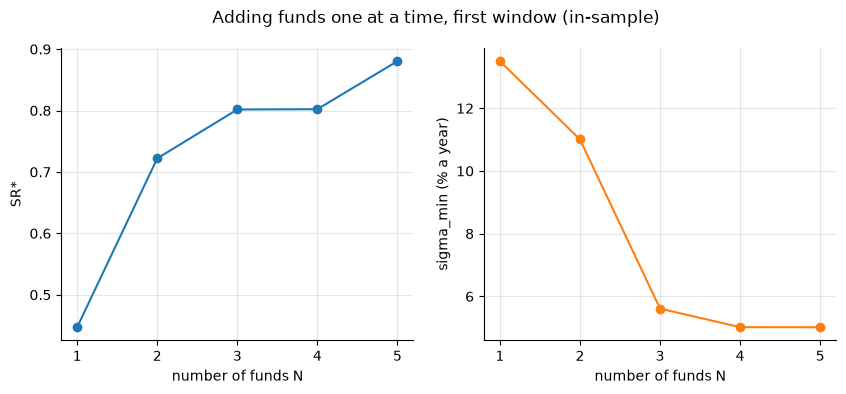

In [14]:
ns, srs, smins = [], [], []
for n in range(1, 6):
    m_, S_ = mu[:n], S[:n, :n]
    if n == 1:
        srs.append(abs(m_[0] - RF) / math.sqrt(S_[0, 0]))
        smins.append(math.sqrt(S_[0, 0]))
    else:
        oo = mv(m_, S_)
        srs.append(math.sqrt(oo["sr2"]))
        smins.append(math.sqrt(oo["s2min"]))
    ns.append(n)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.plot(ns, srs, marker="o")
a1.set(xlabel="number of funds N", ylabel="SR*", xticks=ns)
a2.plot(ns, 100 * np.array(smins), marker="o", color="C1")
a2.set(xlabel="number of funds N", ylabel="sigma_min (% a year)", xticks=ns)
fig.suptitle("Adding funds one at a time, first window (in-sample)")
plt.show()
# your code: repeat on the test rows (Xt) and compare the in-sample gains with the test period's